# Case study — decision-tree distributional query

Run the DT approach end-to-end on a dataset of your choice, the same pipeline the
UI (`quaero_ui.py`) uses — both import it from `quaero_core.py`.

1. **Dataset** — point at a CSV; `datasets/metadata.py` supplies its delimiter,
   target(s), id columns and categoricals when it knows the file.
2. **Preprocessing** — drop ids and the *other* declared targets, integer-encode
   categoricals, drop NaN/inf rows, bin the target with Scott's rule.
3. **Index** — purity-grown decision tree over the descriptors.
4. **Query** — specify the target distribution as a mixture, then query by
   cardinality (disjoint subsets under a TVD threshold) or by number of boxes.
5. **Plots** — the specified pdf, and each found subset against the full data,
   as in the UI, plus TVD / JSD / KLD / Hellinger / BC.

Edit the cells marked **✏️**, then run top to bottom.

In [ ]:
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from quaero_core import (METADATA, read_dataset, target_candidates, prepare_frame,
                         default_dataset, bin_target, _bin_centers, build_index,
                         make_pdf, target_props, feasibility, find_multiple_subsets,
                         find_best_boxes, selected_rows, dist_metrics,
                         simplify_rule, rule_to_str, rank_by_rule_length)
print(f"metadata known for {len(METADATA)} datasets")

## 1. Dataset ✏️

- `DATASET_PATH` — a CSV/TSV on disk. The file's stem (e.g. `winequality-red`) is
  looked up in `datasets/metadata.py`; unknown files have their separator sniffed.
  Set it to `None` to use the built-in synthetic dataset.
- `TARGET` — `None` picks the first target declared in the metadata (or the first
  non-id column for unknown files). Set it explicitly for multi-target datasets.
- `MAX_ROWS` — optional seeded subsample *after* cleaning, to keep the index build
  quick on large files. `None` keeps every row.

In [5]:
DATASET_PATH = "datasets/factory.csv"
TARGET = 'remaining_useful_life_hours'
MAX_ROWS = None
SEED = 0

## 2. Load + preprocess

In [6]:
if DATASET_PATH is None or not Path(DATASET_PATH).exists():
    if DATASET_PATH is not None:
        print(f"!! {DATASET_PATH} not found -- falling back to the SYNTHETIC dataset !!")
    df, TARGET = default_dataset()
    raw, meta, name = df.copy(), {}, "synthetic (default)"
else:
    raw, meta, name = read_dataset(DATASET_PATH)
    cands = target_candidates(raw, meta)
    if TARGET is None:
        TARGET = cands[0]
    if TARGET not in raw.columns:
        raise ValueError(f"TARGET {TARGET!r} not in columns {list(raw.columns)}")
    df = prepare_frame(raw, TARGET, meta)

if MAX_ROWS is not None and len(df) > MAX_ROWS:
    df = df.sample(MAX_ROWS, random_state=SEED).reset_index(drop=True)

# what preprocessing did (mirrors prepare_frame's rules)
dropped_ids    = [c for c in meta.get("id_variables", []) if c in raw.columns]
dropped_tgts   = [c for c in meta.get("target_variable", []) if c in raw.columns and c != TARGET]
encoded        = [c for c in raw.columns if c in df.columns
                  and not pd.api.types.is_numeric_dtype(raw[c])]
desc_cols      = [c for c in df.columns if c != TARGET]

print(f"dataset        : {name}   ({'metadata' if meta else 'no metadata, separator sniffed'})")
if meta:
    print(f"delimiter      : {meta.get('delim')!r}")
    print(f"declared target: {meta.get('target_variable')}")
print(f"target         : {TARGET}")
print(f"raw shape      : {raw.shape}")
print(f"dropped ids    : {dropped_ids or '-'}")
print(f"dropped targets: {dropped_tgts or '-'}   (other declared targets, so they cannot leak)")
print(f"encoded        : {encoded or '-'}   (non-numeric -> integer codes)")
print(f"rows dropped   : {len(raw) - len(df) if MAX_ROWS is None else 'n/a (subsampled)'}   (NaN/inf)")
print(f"final shape    : {df.shape}   -> {len(desc_cols)} descriptors")
df.head()

dataset        : factory   (metadata)
delimiter      : ','
declared target: ['machine_failure', 'failure_type', 'remaining_useful_life_hours']
target         : remaining_useful_life_hours
raw shape      : (100000, 72)
dropped ids    : ['machine_id', 'monitoring_id', 'timestamp']
dropped targets: ['machine_failure', 'failure_type']   (other declared targets, so they cannot leak)
encoded        : ['factory_id', 'production_line', 'machine_type', 'manufacturer', 'model', 'factory_shift', 'last_maintenance_date', 'maintenance_type', 'maintenance_priority']   (non-numeric -> integer codes)
rows dropped   : 0   (NaN/inf)
final shape    : (100000, 67)   -> 66 descriptors


,factory_id,production_line,machine_type,manufacturer,model,installation_year,machine_age,machine_capacity,machine_power_kw,machine_weight_kg,...,cooling_system_health,temperature_anomaly_score,vibration_anomaly_score,pressure_anomaly_score,electrical_anomaly_score,energy_anomaly_score,machine_health_score,failure_probability,maintenance_priority,remaining_useful_life_hours
0,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,74.3,38.4,8.6,15.4,9.0,54.1,80.6,0.4,0.0,14591
1,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,74.3,44.1,17.5,9.8,0.3,44.7,80.6,0.4,0.0,14363
2,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,74.3,38.3,10.7,30.8,3.1,47.2,80.6,0.4,0.0,14639
3,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,74.2,40.5,11.2,14.5,13.8,51.7,80.5,0.5,0.0,14459
4,0.0,0.0,0.0,0.0,0.0,2022,4,404.7,144.1,2826.9,...,74.2,32.7,22.3,8.6,9.3,52.2,80.5,0.5,0.0,14670


## 3. Build the decision-tree index

index built in 14.27s: 84137 nodes, 42069 leaves, 98 target bins (Scott's rule), N=100000
target range [8856, 1.891e+04], mean 1.339e+04, std 1365


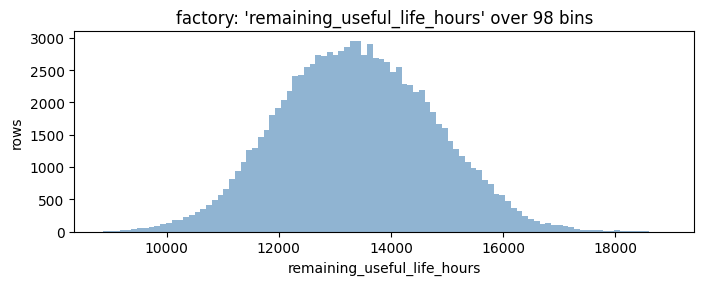

In [7]:
t0 = time.perf_counter()
ix = build_index(df, TARGET)
build_sec = time.perf_counter() - t0

N = len(df)
n_bins = ix["n_bins"]
bin_ids, _ = bin_target(df, TARGET)
centers = _bin_centers(df, TARGET, n_bins)
avail = {b: int((bin_ids == b).sum()) for b in range(n_bins)}
tmin, tmax = float(df[TARGET].min()), float(df[TARGET].max())
edges = np.linspace(tmin, tmax, n_bins + 1)

print(f"index built in {build_sec:.2f}s: {ix['n']} nodes, {len(ix['leaves'])} leaves, "
      f"{n_bins} target bins (Scott's rule), N={N}")
print(f"target range [{tmin:.4g}, {tmax:.4g}], mean {df[TARGET].mean():.4g}, std {df[TARGET].std():.4g}")

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.hist(df[TARGET], bins=edges, color="steelblue", alpha=0.6)
ax.set_title(f"{name}: '{TARGET}' over {n_bins} bins")
ax.set_xlabel(TARGET); ax.set_ylabel("rows")
plt.show()

## 4. Specify the distributional query ✏️

`COMPONENTS` is a mixture: a list of `(family, params, weight)`. Weights are
normalised. Families and their parameters:

| family | params |
|---|---|
| `gaussian` | `loc`, `scale` |
| `exponential` | `loc`, `scale` |
| `uniform` | `loc`, `scale` (support `[loc, loc+scale]`) |
| `beta` | `a`, `b`, and `loc`, `scale` to stretch it off `[0, 1]` onto the target's range |
| `weibull` | `shape`, `scale`, `loc` |
| `lognormal` | `mu`, `sigma`, `loc` (ln(X − loc) ~ N(mu, sigma²)) |

Shapes, scales and `sigma` must be > 0; an invalid value raises an error.

The defaults below put one Gaussian at the target's mean with half its spread.
`MU`, `SD`, `tmin` and `tmax` are there to help you place components.

In [ ]:
MU, SD = float(12000), float(df[TARGET].std())

COMPONENTS = [
    # ("gaussian", {"loc": MU, "scale": SD / 2}, 1.0),
    # ("gaussian", {"loc": MU + SD, "scale": SD / 4}, 0.5),          # a second mode
    # ("beta", {"a": 2, "b": 5, "loc": tmin, "scale": tmax - tmin}, 1.0),
    ("weibull",   {"shape": 15, "scale": SD, "loc": 10000}, 1.0),
    # ("lognormal", {"mu": np.log(MU - tmin), "sigma": 0.5, "loc": tmin}, 1.0),
]

CARDINALITY_PCT = 1      # size of each subset, % of N   (cardinality query)
TVD_THRESHOLD   = 0.10    # stop extracting subsets once TVD exceeds this
N_BOXES         = 4       # number of bounding boxes        (box query)
RANK_BY         = "terms" # sort subsets by simplified rule: "terms" or "literals" first

## 5. Specified target pdf + feasibility

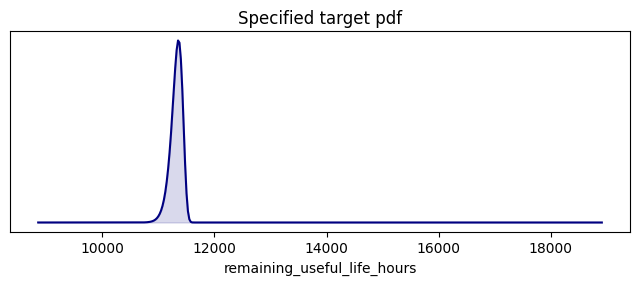

feasible at 1%   (max ~ 3% of rows)


In [60]:
pdf = make_pdf(COMPONENTS)
p = target_props(COMPONENTS, centers)          # target proportion per bin
if p is None:
    raise ValueError("the mixture puts no mass on the target's range -- adjust COMPONENTS")
target = {b: float(p[b]) for b in range(n_bins)}

xs = np.linspace(tmin, tmax, 400)
ys = np.array([pdf(x) for x in xs])
fig, ax = plt.subplots(figsize=(8, 2.6))
ax.plot(xs, ys, color="navy")
ax.fill_between(xs, ys, color="navy", alpha=0.15)
ax.set_title("Specified target pdf"); ax.set_xlabel(TARGET); ax.set_yticks([])
plt.show()

ok, max_pct, b, need, have = feasibility(p, avail, N, CARDINALITY_PCT)
if ok:
    print(f"feasible at {CARDINALITY_PCT}%   (max ~ {max_pct:.0f}% of rows)")
else:
    print(f"INFEASIBLE at {CARDINALITY_PCT}%: bin {b} needs {need:.0f} rows but has {have}"
          f"   (max ~ {max_pct:.0f}%)")

### Plot + report helpers

`show(result, label)` draws what the UI's bottom panel draws (full-data histogram,
the subset's histogram, the specified pdf), next to a per-bin comparison of the
proportions the metrics are computed on, then prints the metrics and the rule.
Pass `save="figures/name.pdf"` to also write the figure.

In [ ]:
def metrics_of(res):
    return dist_metrics(res["got"], res["tc"])

def show(res, label, max_terms=20, save=None):
    rows = res["rows"]
    sel = df[TARGET].to_numpy()[rows]
    m = metrics_of(res)
    simple = res["simple"]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.2),
                                 gridspec_kw=dict(width_ratios=[3, 2]))
    # left: as in the UI
    a1.hist(df[TARGET], bins=edges, density=True, alpha=0.35, color="steelblue",
            label="full dataset")
    if len(sel):
        a1.hist(sel, bins=edges, density=True, alpha=0.75, color="tomato",
                label=f"{label} (n={len(sel)})")
    a1.plot(xs, ys, "k--", lw=1.3, label="specified pdf")
    a1.set_title(f"{label} — TVD={m['tvd']:.3f}, "
                 f"{simple['n_terms']} terms / {simple['n_literals']} lits")
    a1.set_xlabel(TARGET); a1.set_yticks([]); a1.legend(fontsize=8)
    # right: the per-bin proportions the metrics compare
    tq = np.array([res["tc"].get(b, 0.0) for b in range(n_bins)], float)
    gq = np.array([res["got"].get(b, 0.0) for b in range(n_bins)], float)
    tq, gq = tq / max(tq.sum(), 1e-12), gq / max(gq.sum(), 1e-12)
    w = 0.4
    a2.bar(np.arange(n_bins) - w / 2, tq, w, color="0.35", label="target")
    a2.bar(np.arange(n_bins) + w / 2, gq, w, color="tomato", label="subset")
    a2.set_title("per-bin proportions"); a2.set_xlabel("target bin")
    a2.legend(fontsize=8)
    fig.tight_layout()
    if save:
        Path(save).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save, bbox_inches="tight")
    plt.show()
    print(f"{label}: rows {len(sel)} / {N}   terms {simple['n_terms']} "
          f"(tree: {res['red']['n_terms']})   literals {simple['n_literals']}   " +
          "   ".join(f"{k.upper()}={v}" for k, v in m.items()))
    print(rule_to_str(simple, max_terms=max_terms))
    # res["simple"]["expr"] holds the same rule as a sympy expression

def table(results, labels):
    return pd.DataFrame([dict(result=l, rows=len(r["rows"]), terms=r["simple"]["n_terms"],
                              literals=r["simple"]["n_literals"],
                              tree_terms=r["red"]["n_terms"], **metrics_of(r))
                         for r, l in zip(results, labels)])

## 6a. Query by cardinality

Disjoint subsets of `CARDINALITY_PCT`% of the rows, each matching the target,
extracted greedily until the next one's TVD exceeds `TVD_THRESHOLD`. Each
subset's tree rule is reduced with sympy (repeated tests on a feature collapse
to one interval; neighbouring boxes merge), and the results are sorted shortest
simplified rule first (`RANK_BY`). `tree_terms` is the length before reduction.

In [ ]:
total = round(CARDINALITY_PCT / 100 * N)
t0 = time.perf_counter()
found = find_multiple_subsets(ix, target, total, TVD_THRESHOLD)
query_sec = time.perf_counter() - t0
t0 = time.perf_counter()
subsets = rank_by_rule_length(found, by=RANK_BY)
print(f"{len(subsets)} disjoint subset(s) under TVD {TVD_THRESHOLD} in {query_sec:.2f}s; "
      f"simplified + sorted by {RANK_BY} in {time.perf_counter() - t0:.2f}s")
table(subsets, [f"subset #{i + 1}" for i in range(len(subsets))])

In [ ]:
SHOW = 0          # which subset to plot (0 = the first / best)
if subsets:
    show(subsets[SHOW], f"subset #{SHOW + 1}")
else:
    print("no subset under the TVD threshold -- raise TVD_THRESHOLD or lower CARDINALITY_PCT")

## 6b. Query by number of boxes

The `N_BOXES` disjoint subtrees (one DNF conjunct each) whose union is closest to
the target in TVD. There is no size constraint here. The rule is then reduced
with sympy like the cardinality results; boxes that touch can merge, so the
simplified rule may have fewer than `N_BOXES` terms.

In [ ]:
t0 = time.perf_counter()
boxes = find_best_boxes(ix, target, N_BOXES)
boxes["rows"] = selected_rows(ix, boxes["labels"])
query_sec = time.perf_counter() - t0
t0 = time.perf_counter()
boxes["simple"] = simplify_rule(boxes["red"]["dnf"])
print(f"best {boxes['n_boxes']} box(es) in {query_sec:.2f}s; simplified in "
      f"{time.perf_counter() - t0:.2f}s to {boxes['simple']['n_terms']} term(s)")
show(boxes, f"{boxes['n_boxes']} box(es)")